# Phase 7 L1 LoRA comparison on Kaggle

Run both configurations in this one self-contained notebook. Each run starts independently from pinned `neurlang/ipa-whisper-base` and uses all 3,629 frozen training clips. Validation uses all 732 clips, the same IPA normalization/CER, and repetition penalty 1.08. The 683-clip test set remains sealed. Compare against full fine-tuning `2e-5`, Epoch 5, CER 47.23950%.

Attach only the private `phase7_f1_train_v1` and `phase5_validation_baseline` datasets. Enable a T4 GPU and Internet. Do not attach model checkpoints or test data.


## Embedded trainer and engineering gate

This code reuses the F1 bundle, feature, target, optimizer, scoring, and checkpoint contract. PEFT adds trainable `q_proj`/`v_proj` adapters in encoder and decoder. The probe checks real gradients, one optimizer update, adapter save, and trainable reload before the full experiment. Progress bars display training updates and validation batches.


In [1]:
"""Phase F1 full fine-tuning on the frozen Nyishi Narration split.

This is a private Kaggle runner. It starts from the pinned pretrained model,
uses lazy CPU feature extraction (no multi-gigabyte feature cache), trains with
FP16 AMP and gradient accumulation, validates with the Phase 6C-equivalent
batch-8 greedy policy, and saves resumable epoch checkpoints. It never reads
the test split.
"""
from __future__ import annotations

import argparse
import copy
import csv
import gc
import hashlib
import json
import math
import random
import re
import time
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import soundfile as sf
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import (
    GenerationConfig,
    WhisperForConditionalGeneration,
    WhisperProcessor,
    get_linear_schedule_with_warmup,
)


MODEL_ID = "neurlang/ipa-whisper-base"
MODEL_REVISION = "949f7c4e4ee374b5202bc5886f6e4552e5ae2371"
EOS_ID = 50257
MAX_LENGTH = 448
EXPECTED_TRAIN = 3629
EXPECTED_VALIDATION = 732
EXPECTED_REFERENCE_CODEPOINTS = 64137


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def safe(root: Path, relative: str) -> Path:
    path = (root / relative).resolve()
    path.relative_to(root.resolve())
    return path


def extract_bundle(archive: Path, bundle_type: str, destination: Path) -> tuple[Path, dict]:
    if archive.is_dir():
        marker = archive / "bundle_record.json"
        return archive, json.loads(marker.read_text())
    with zipfile.ZipFile(archive) as zf:
        markers = [n for n in zf.namelist() if n.endswith("bundle_record.json")]
        matches = [(n, json.loads(zf.read(n))) for n in markers]
        matches = [(n, r) for n, r in matches if r.get("bundle_type") == bundle_type]
        assert len(matches) == 1, f"Expected one {bundle_type} marker in {archive}"
        marker_name, record = matches[0]
        root = destination / bundle_type
        root.mkdir(parents=True, exist_ok=True)
        for member in tqdm(zf.infolist(), desc=f"Extracting {bundle_type}", unit="file"):
            target = (root / member.filename).resolve()
            target.relative_to(root.resolve())
        for member in tqdm(zf.infolist(), desc=f"Writing {bundle_type}", unit="file"):
            zf.extract(member, root)
        return (root / Path(marker_name).parent).resolve(), record


def discover_bundle(root: Path, bundle_type: str) -> Path:
    candidates = []
    for marker in root.rglob("bundle_record.json"):
        try:
            if json.loads(marker.read_text()).get("bundle_type") == bundle_type:
                candidates.append(marker.parent)
        except (OSError, json.JSONDecodeError):
            pass
    for archive in root.rglob("*.zip"):
        try:
            with zipfile.ZipFile(archive) as zf:
                for name in zf.namelist():
                    if name.endswith("bundle_record.json") and json.loads(zf.read(name)).get("bundle_type") == bundle_type:
                        candidates.append(archive)
        except (OSError, zipfile.BadZipFile, json.JSONDecodeError):
            pass
    candidates = sorted(set(candidates))
    assert len(candidates) == 1, f"Expected one {bundle_type} input, found {len(candidates)}: {candidates}"
    return candidates[0]


def verify_bundle(root: Path, record: dict, expected_partition: str) -> None:
    sums = root / "SHA256SUMS.txt"
    if sums.exists():
        entries = [line.split("  ", 1) for line in sums.read_text().splitlines() if line]
        for expected, relative in tqdm(entries, desc="Verifying bundle checksums", unit="file"):
            assert sha256(safe(root, relative)) == expected, f"Checksum failed: {relative}"
    # Validation bundles declare evaluation_partition/contains_test_audio;
    # the full F1 training bundle declares contains_validation_or_test_audio.
    # Accept either explicit schema without weakening the split checks.
    if "evaluation_partition" in record:
        assert record["evaluation_partition"] == expected_partition
    if "contains_test_audio" in record:
        assert record["contains_test_audio"] is False
    if "contains_validation_or_test_audio" in record:
        assert record["contains_validation_or_test_audio"] is False


def normalize(value: str) -> str:
    return re.sub(r" {2,}", " ", unicodedata.normalize("NFD", str(value)).strip())


def edit_counts(reference: str, hypothesis: str) -> tuple[int, int, int]:
    ref, hyp = list(reference), list(hypothesis)
    distance = [[0] * (len(hyp) + 1) for _ in range(len(ref) + 1)]
    for i in range(len(ref) + 1):
        distance[i][0] = i
    for j in range(len(hyp) + 1):
        distance[0][j] = j
    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):
            distance[i][j] = min(
                distance[i - 1][j] + 1,
                distance[i][j - 1] + 1,
                distance[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]),
            )
    substitutions = deletions = insertions = 0
    i, j = len(ref), len(hyp)
    while i or j:
        if i and j and ref[i - 1] == hyp[j - 1] and distance[i][j] == distance[i - 1][j - 1]:
            i, j = i - 1, j - 1
        elif i and j and distance[i][j] == distance[i - 1][j - 1] + 1:
            substitutions += 1; i, j = i - 1, j - 1
        elif i and distance[i][j] == distance[i - 1][j] + 1:
            deletions += 1; i -= 1
        else:
            insertions += 1; j -= 1
    return substitutions, deletions, insertions


def main(argv: list[str] | None = None) -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train-input", type=Path)
    parser.add_argument("--validation-input", type=Path)
    parser.add_argument("--output", type=Path, default=Path("/kaggle/working/phase7_F1_private"))
    parser.add_argument("--resume", type=Path, default=None, help="epoch_N directory from this exact F1 run")
    parser.add_argument("--physical-batch", type=int, default=2)
    parser.add_argument("--accumulation", type=int, default=4)
    parser.add_argument("--validation-batch", type=int, default=8)
    parser.add_argument("--max-epochs", type=int, default=10)
    parser.add_argument("--patience", type=int, default=3)
    parser.add_argument("--learning-rate", type=float, default=1e-4)
    parser.add_argument("--lora-rank", type=int, default=8)
    parser.add_argument("--lora-alpha", type=int, default=16)
    parser.add_argument("--lora-dropout", type=float, default=0.05)
    parser.add_argument("--probe-only", action="store_true")
    parser.add_argument("--repetition-penalty", type=float, default=1.0)
    parser.add_argument("--weight-decay", type=float, default=0.01)
    parser.add_argument("--seed", type=int, default=0)
    args, unknown = parser.parse_known_args(argv)
    if argv is not None and unknown:
        raise ValueError(f"Unknown arguments: {unknown}")
    assert torch.cuda.is_available(), "A CUDA GPU is required."
    assert args.physical_batch * args.accumulation == 8
    assert args.validation_batch == 8
    assert (args.lora_rank, args.lora_alpha) in ((8, 16), (16, 32))
    assert args.lora_dropout == 0.05 and args.learning_rate in (1e-4, 2e-5)
    input_root = Path("/kaggle/input")
    if args.train_input is None:
        args.train_input = discover_bundle(input_root, "phase7_f1_train_v1")
    if args.validation_input is None:
        args.validation_input = discover_bundle(input_root, "phase5_validation_baseline")
    args.output.mkdir(parents=True, exist_ok=True)
    extracted = args.output / "_extracted_inputs"
    train_root, train_record = extract_bundle(args.train_input, "phase7_f1_train_v1", extracted)
    val_root, val_record = extract_bundle(args.validation_input, "phase5_validation_baseline", extracted)
    verify_bundle(train_root, train_record, "train")
    verify_bundle(val_root, val_record, "validation")
    assert train_record["clips"] == EXPECTED_TRAIN and val_record["clips"] == EXPECTED_VALIDATION
    assert train_record.get("contains_validation_or_test_audio") is False

    with (train_root / "train_manifest.csv").open(newline="", encoding="utf-8") as stream:
        train_rows = list(csv.DictReader(stream))
    with (val_root / "validation_manifest.csv").open(newline="", encoding="utf-8") as stream:
        val_rows = list(csv.DictReader(stream))
    assert len(train_rows) == EXPECTED_TRAIN and len(val_rows) == EXPECTED_VALIDATION
    assert sum(len(normalize(row["reference"])) for row in val_rows) == EXPECTED_REFERENCE_CODEPOINTS
    assert {row["sample_id"] for row in train_rows}.isdisjoint({row["sample_id"] for row in val_rows})

    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed); torch.cuda.manual_seed_all(args.seed)
    processor = WhisperProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    generation_config = GenerationConfig.from_dict(json.loads((val_root / "generation_config.json").read_text()))
    # Reproduce the corrected Phase 7 validation policy. Only the explicitly
    # declared repetition penalty may differ between matched experiments.
    generation_config.max_new_tokens = None
    generation_config.do_sample = False
    generation_config.num_beams = 1
    generation_config.num_return_sequences = 1
    generation_config.no_repeat_ngram_size = 0
    generation_config.suppress_tokens = []
    generation_config.forced_decoder_ids = None
    generation_config.language = None
    generation_config.task = "transcribe"
    generation_config.return_timestamps = False
    generation_config.max_length = MAX_LENGTH
    generation_config.begin_suppress_tokens = [220, EOS_ID]
    generation_config.return_dict_in_generate = True
    generation_config.output_scores = False
    generation_config.pad_token_id = EOS_ID
    generation_config.eos_token_id = EOS_ID
    generation_config.repetition_penalty = args.repetition_penalty
    assert generation_config.eos_token_id == EOS_ID and generation_config.max_length == MAX_LENGTH
    assert generation_config.decoder_start_token_id == 50258
    assert generation_config.forced_decoder_ids is None
    assert generation_config.language is None and generation_config.task == "transcribe"
    assert generation_config.no_repeat_ngram_size == 0

    def read_audio(root: Path, row: dict) -> np.ndarray:
        path = safe(root, row["audio_file"])
        audio, sample_rate = sf.read(path, dtype="float32", always_2d=True)
        assert sample_rate == 16000 and audio.shape[1] == 1
        assert 0.5 <= len(audio) / sample_rate < 30
        return audio[:, 0]

    def make_features(
        root: Path,
        rows: list[dict],
        *,
        return_attention_mask: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        audios = [read_audio(root, row) for row in rows]
        # Force Whisper's fixed 30-second window for batched inputs. Plain
        # padding=True pads only to the longest item in this batch and can
        # return a time axis different from the required 3,000 frames.
        packed = processor.feature_extractor(
            audios,
            sampling_rate=16000,
            return_tensors="pt",
            return_attention_mask=return_attention_mask,
            padding="max_length",
            truncation=True,
            max_length=480000,
        )
        features = packed.input_features
        if features.ndim == 2:
            features = features.unsqueeze(0)
        assert features.ndim == 3 and features.shape[1] == 80, (
            f"Unexpected Whisper feature shape before window normalization: {tuple(features.shape)}"
        )
        # Defensive normalization for minor Transformers/feature-extractor
        # patch differences: the model contract is always 80 x 3000.
        if features.shape[-1] > 3000:
            features = features[..., :3000]
        elif features.shape[-1] < 3000:
            features = F.pad(features, (0, 3000 - features.shape[-1]))
        assert tuple(features.shape[1:]) == (80, 3000)
        assert torch.isfinite(features).all().item(), "Non-finite Whisper features"
        features = features.to(dtype=torch.float32)
        if not return_attention_mask:
            return features
        attention_mask = packed.attention_mask
        if attention_mask.ndim == 1:
            attention_mask = attention_mask.unsqueeze(0)
        if attention_mask.shape[-1] > 3000:
            attention_mask = attention_mask[..., :3000]
        elif attention_mask.shape[-1] < 3000:
            attention_mask = F.pad(attention_mask, (0, 3000 - attention_mask.shape[-1]))
        assert tuple(attention_mask.shape) == (len(rows), 3000)
        return features, attention_mask.long()

    def make_labels(rows: list[dict]) -> torch.Tensor:
        # Use WhisperTokenizerFast.__call__ for batched tokenization. This
        # avoids the fast-tokenizer warning caused by encode-then-pad.
        references = [normalize(row["reference"]) for row in rows]
        encoded = processor.tokenizer(
            references,
            add_special_tokens=False,
            padding=True,
            return_tensors="pt",
        )
        token_lengths = encoded["attention_mask"].sum(dim=1).tolist()
        # Add one column so every example retains an explicit EOS token.
        input_ids = F.pad(encoded["input_ids"], (0, 1), value=processor.tokenizer.pad_token_id)
        attention_mask = F.pad(encoded["attention_mask"], (0, 1), value=0)
        for row_index, (reference, token_length) in enumerate(zip(references, token_lengths)):
            ids = encoded["input_ids"][row_index, :token_length].tolist()
            assert processor.tokenizer.decode(ids, skip_special_tokens=False, clean_up_tokenization_spaces=False) == reference
            assert token_length + 1 < MAX_LENGTH
            input_ids[row_index, token_length] = EOS_ID
            attention_mask[row_index, token_length] = 1
        labels = input_ids.masked_fill(attention_mask.ne(1), -100)
        for row_index, token_length in enumerate(token_lengths):
            assert labels[row_index, token_length].item() == EOS_ID
        return labels

    device = torch.device("cuda:0")
    from peft import LoraConfig, PeftModel, get_peft_model
    base = WhisperForConditionalGeneration.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, dtype=torch.float32, attn_implementation="sdpa"
    )
    base.config.use_cache = False
    targets = [(name, type(module).__name__) for name, module in base.named_modules()
               if name.endswith(("q_proj", "v_proj"))]
    assert targets and any("encoder" in name for name, _ in targets)
    assert any("decoder" in name for name, _ in targets)
    assert all(kind == "Linear" for _, kind in targets), targets
    print("LoRA targets:", targets)
    if args.resume:
        model = PeftModel.from_pretrained(
            base, args.resume / "adapter", is_trainable=True
        )
    else:
        lora = LoraConfig(
            r=args.lora_rank, lora_alpha=args.lora_alpha,
            lora_dropout=args.lora_dropout, target_modules=["q_proj", "v_proj"],
            bias="none",
        )
        model = get_peft_model(base, lora)
    model = model.to(device).train()
    model.config.use_cache = False
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    assert 0 < trainable < total / 10
    assert all(("lora_" in name) == parameter.requires_grad
               for name, parameter in model.named_parameters())
    print({"trainable": trainable, "total": total, "percent": 100*trainable/total})
    decay, no_decay = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            (no_decay if name.endswith("bias") or "layer_norm" in name.lower() else decay).append(parameter)
    optimizer = torch.optim.AdamW(
        [{"params": decay, "weight_decay": args.weight_decay}, {"params": no_decay, "weight_decay": 0.0}],
        lr=args.learning_rate,
    )
    micro_batches = math.ceil(len(train_rows) / args.physical_batch)
    steps_per_epoch = math.ceil(micro_batches / args.accumulation)
    total_steps = steps_per_epoch * args.max_epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, max(1, math.ceil(0.05 * total_steps)), total_steps)
    scaler = torch.amp.GradScaler("cuda", init_scale=256.0)
    fingerprint = hashlib.sha256(json.dumps({
        "model": MODEL_ID, "revision": MODEL_REVISION, "train": train_record.get("manifest_sha256"),
        "validation": val_record.get("manifest_sha256"), "seed": args.seed,
        "physical_batch": args.physical_batch, "accumulation": args.accumulation,
        "validation_batch": args.validation_batch, "max_epochs": args.max_epochs,
        "patience": args.patience, "learning_rate": args.learning_rate,
        "lora_rank": args.lora_rank, "lora_alpha": args.lora_alpha,
        "lora_dropout": args.lora_dropout, "peft_version": __import__("peft").__version__,
        "generation": generation_config.to_dict(),
    }, sort_keys=True, default=str).encode()).hexdigest()
    start_epoch = 0; completed_steps = 0; history = []; best_cer = float("inf"); best_epoch = None; stale_epochs = 0
    if args.resume:
        state = torch.load(args.resume / "training_state.pt", map_location="cpu", weights_only=False)
        assert state["fingerprint"] == fingerprint and state["epoch"] < args.max_epochs
        optimizer.load_state_dict(state["optimizer"]); scheduler.load_state_dict(state["scheduler"]); scaler.load_state_dict(state["scaler"])
        for item in optimizer.state.values():
            for key, value in item.items():
                if isinstance(value, torch.Tensor): item[key] = value.to(device)
        random.setstate(state["python_rng"]); np.random.set_state(state["numpy_rng"]); torch.set_rng_state(state["torch_rng"]); torch.cuda.set_rng_state_all(state["cuda_rng"])
        start_epoch = state["epoch"]; completed_steps = state["completed_steps"]; history = state["history"]; best_cer = state["best_cer"]; best_epoch = state["best_epoch"]; stale_epochs = state.get("stale_epochs", 0)
    print({"train_clips": len(train_rows), "validation_clips": len(val_rows), "steps_per_epoch": steps_per_epoch, "max_epochs": args.max_epochs, "patience": args.patience, "fingerprint": fingerprint})

    def evaluate(epoch: int) -> tuple[dict, list[dict]]:
        model.eval(); model.config.use_cache = True; records = []; started = time.perf_counter()
        for begin in tqdm(range(0, len(val_rows), args.validation_batch), desc=f"Epoch {epoch} validation", unit="batch"):
            rows = val_rows[begin:begin + args.validation_batch]
            features, attention_mask = make_features(
                val_root, rows, return_attention_mask=True
            )
            features = features.to(device)
            attention_mask = attention_mask.to(device)
            with torch.inference_mode():
                generated = model.generate(
                    input_features=features,
                    attention_mask=attention_mask,
                    generation_config=copy.deepcopy(generation_config),
                )
            for row, sequence in zip(rows, generated.sequences.detach().cpu().tolist()):
                ids = sequence[:sequence.index(EOS_ID) + 1] if EOS_ID in sequence else sequence[:MAX_LENGTH]
                raw = processor.tokenizer.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=False); hypothesis = normalize(raw); reference = normalize(row["reference"])
                substitutions, deletions, insertions = edit_counts(reference, hypothesis)
                records.append({"sample_id": row["sample_id"], "reference": reference, "raw_prediction": raw, "normalized_prediction": hypothesis, "token_ids": ids, "eos": bool(ids and ids[-1] == EOS_ID), "cap_without_eos": len(ids) >= MAX_LENGTH and (not ids or ids[-1] != EOS_ID), "S": substitutions, "D": deletions, "I": insertions, "duration_seconds": float(row["duration_seconds"])})
            del features, attention_mask, generated
        model.train(); model.config.use_cache = False; gc.collect(); torch.cuda.empty_cache()
        reference_codepoints = sum(len(r["reference"]) for r in records); S = sum(r["S"] for r in records); D = sum(r["D"] for r in records); I = sum(r["I"] for r in records)
        return {"clips": len(records), "reference_codepoints": reference_codepoints, "S": S, "D": D, "I": I, "edit_count": S + D + I, "corpus_cer": (S + D + I) / reference_codepoints, "eos_count": sum(r["eos"] for r in records), "cap_without_eos": sum(r["cap_without_eos"] for r in records), "replacement_character_outputs": sum("�" in r["normalized_prediction"] for r in records), "elapsed_seconds": time.perf_counter() - started}, records

    if args.probe_only:
        # One real forward/backward/update; restore by loading the saved adapter.
        # The full-run warmup scheduler initializes optimizer LR to zero.
        # Give this isolated probe a nonzero LR so a successful step
        # must actually change an adapter weight. Full runs keep warmup.
        for group in optimizer.param_groups:
            group["lr"] = args.learning_rate
        assert all(group["lr"] > 0 for group in optimizer.param_groups)
        rows = train_rows[:args.physical_batch]
        features = make_features(train_root, rows).to(device)
        labels = make_labels(rows).to(device)
        # FP16 may overflow at the initial scale. Retry exactly this batch
        # with the reduced scaler value; require an actual optimizer step.
        for attempt in range(8):
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                loss = model(input_features=features, labels=labels).loss
            assert torch.isfinite(loss).item(), "Nonfinite probe loss"
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            grads = [p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
            if not grads or not all(torch.isfinite(g).all().item() for g in grads):
                old_scale = scaler.get_scale()
                scaler.step(optimizer); scaler.update()
                assert scaler.get_scale() < old_scale, "AMP did not reduce on overflow"
                continue
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
            assert torch.isfinite(norm).item() and float(norm) > 0
            changed = [(p, p.detach().clone()) for p in model.parameters()
                       if p.requires_grad and p.grad is not None and torch.count_nonzero(p.grad).item()]
            assert changed, "No nonzero LoRA gradients"
            old_scale = scaler.get_scale()
            scaler.step(optimizer); scaler.update()
            if scaler.get_scale() < old_scale:
                continue
            assert any(not torch.equal(before, p.detach()) for p, before in changed), "No LoRA weight changed after a finite optimizer step"
            break
        else:
            raise RuntimeError("Probe could not complete a finite update after 8 AMP retries")
        gate_path = args.output / "probe_adapter"
        model.save_pretrained(gate_path, safe_serialization=True)
        del model, optimizer, features, labels, grads, changed
        gc.collect(); torch.cuda.empty_cache()
        base2 = WhisperForConditionalGeneration.from_pretrained(
            MODEL_ID, revision=MODEL_REVISION, dtype=torch.float32
        )
        restored = PeftModel.from_pretrained(base2, gate_path, is_trainable=True)
        assert any(p.requires_grad for p in restored.parameters())
        print({"probe": "PASS", "loss": float(loss), "grad_norm": float(norm),
               "adapter_reload": True, "peak_mib": torch.cuda.max_memory_allocated(device)/2**20})
        return
    run_started = time.perf_counter(); torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(start_epoch + 1, args.max_epochs + 1):
        model.train(); model.config.use_cache = False; indices = list(range(len(train_rows))); random.shuffle(indices); groups = [indices[i:i + args.physical_batch] for i in range(0, len(indices), args.physical_batch)]; losses = []; epoch_updates = 0; amp_retries = 0; epoch_started = time.perf_counter()
        for begin in tqdm(range(0, len(groups), args.accumulation), desc=f"Epoch {epoch} training", unit="update"):
            accumulation_groups = groups[begin:begin + args.accumulation]
            for attempt in range(8):
                optimizer.zero_grad(set_to_none=True); finite = True; group_losses = []
                try:
                    for group in accumulation_groups:
                        rows = [train_rows[i] for i in group]; features = make_features(train_root, rows).to(device); labels = make_labels(rows).to(device)
                        with torch.autocast(device_type="cuda", dtype=torch.float16): loss = model(input_features=features, labels=labels).loss
                        if not torch.isfinite(loss).item(): raise FloatingPointError("nonfinite forward loss")
                        group_losses.append(float(loss.detach())); scaler.scale(loss / len(accumulation_groups)).backward(); del features, labels
                    scaler.unscale_(optimizer); grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True, foreach=False); assert float(grad_norm) > 0
                    old_scale = scaler.get_scale(); scaler.step(optimizer); scaler.update()
                    if scaler.get_scale() < old_scale: amp_retries += 1; continue
                    scheduler.step(); completed_steps += 1; epoch_updates += 1; losses.extend(group_losses); break
                except torch.cuda.OutOfMemoryError as exc:
                    torch.cuda.empty_cache(); raise RuntimeError("CUDA OOM. Restart with --physical-batch 1 --accumulation 8; do not change the effective batch size.") from exc
            else: raise RuntimeError("No finite AMP update after eight attempts.")
        train_memory = torch.cuda.max_memory_allocated(device) / 1024**2
        validation, predictions = evaluate(epoch)
        improved = validation["corpus_cer"] < best_cer
        if improved: best_cer = validation["corpus_cer"]; best_epoch = epoch; stale_epochs = 0
        else: stale_epochs += 1
        record = {"epoch": epoch, "updates": epoch_updates, "cumulative_updates": completed_steps, "training_loss": sum(losses) / len(losses), "amp_retries": amp_retries, "train_peak_allocated_mib": train_memory, "epoch_seconds": time.perf_counter() - epoch_started, "validation": validation}
        history.append(record); checkpoint = args.output / f"epoch_{epoch:02d}"; checkpoint.mkdir(exist_ok=True); model.save_pretrained(checkpoint / "adapter", safe_serialization=True); torch.save({"fingerprint": fingerprint, "epoch": epoch, "completed_steps": completed_steps, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "python_rng": random.getstate(), "numpy_rng": np.random.get_state(), "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all(), "history": history, "best_cer": best_cer, "best_epoch": best_epoch, "stale_epochs": stale_epochs}, checkpoint / "training_state.pt")
        (args.output / f"validation_epoch_{epoch:02d}_private.jsonl").write_text("\n".join(json.dumps(p, ensure_ascii=False) for p in predictions) + "\n")
        (args.output / "aggregate_history.json").write_text(json.dumps(history, indent=2) + "\n")
        print({"epoch": epoch, "validation_cer_percent": 100 * validation["corpus_cer"], "best_epoch": best_epoch, "stale_epochs": stale_epochs, "train_peak_allocated_mib": train_memory, "validation_seconds": validation["elapsed_seconds"]})
        if stale_epochs >= args.patience: print(f"Early stopping after {args.patience} non-improving validation epochs."); break
    report = {"experiment": "L1 LoRA", "status": "complete", "lora_rank": args.lora_rank,
              "lora_alpha": args.lora_alpha, "lora_dropout": args.lora_dropout,
              "trainable_parameters": trainable, "total_parameters": total,
              "target_modules": targets, "peft_version": __import__("peft").__version__, "model_id": MODEL_ID, "model_revision": MODEL_REVISION, "train_clips": len(train_rows), "train_hours": train_record["hours"], "validation_clips": len(val_rows), "validation_hours": val_record["hours"], "test_data_used": False, "seed": args.seed, "physical_batch": args.physical_batch, "accumulation": args.accumulation, "effective_batch": 8, "validation_batch": args.validation_batch, "learning_rate": args.learning_rate, "repetition_penalty": args.repetition_penalty, "weight_decay": args.weight_decay, "max_epochs": args.max_epochs, "patience": args.patience, "best_epoch": best_epoch, "best_validation_cer": best_cer, "completed_steps": completed_steps, "total_wall_seconds": time.perf_counter() - run_started, "peak_allocated_mib": torch.cuda.max_memory_allocated(device) / 1024**2, "peak_reserved_mib": torch.cuda.max_memory_reserved(device) / 1024**2, "history": history}
    (args.output / "L1_report_private.json").write_text(json.dumps(report, indent=2) + "\n"); print("L1 complete; best epoch", best_epoch, "CER", 100 * best_cer)




In [2]:
# Discover the frozen inputs by bundle marker and keep experiments separate.
from pathlib import Path
import json, gc
ROOT = Path('/kaggle/working/phase7_L1_private')
TRAIN = discover_bundle(Path('/kaggle/input'), 'phase7_f1_train_v1')
VAL = discover_bundle(Path('/kaggle/input'), 'phase5_validation_baseline')
ROOT.mkdir(parents=True, exist_ok=True)
print({'training':str(TRAIN), 'validation':str(VAL)})

def args_for(rank, output, extra=None, lr=1e-4):
    return ['--train-input',str(TRAIN),'--validation-input',str(VAL),
            '--output',str(output),'--lora-rank',str(rank),
            '--lora-alpha',str(2*rank),'--lora-dropout','0.05',
            '--learning-rate',str(lr),'--repetition-penalty','1.08',
            '--physical-batch','2','--accumulation','4','--validation-batch','8',
            '--max-epochs','10','--patience','3','--seed','0'] + (extra or [])

# Run the small engineering gate once; this does not enter either comparison history.
main(args_for(8, ROOT/'engineering_gate', ['--probe-only']))


{'training': '/kaggle/input/datasets/kanchanpotdar/phase-7-f1-train-bundle/phase7_f1_train_bundle', 'validation': '/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle'}


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

LoRA targets: [('model.encoder.layers.0.self_attn.v_proj', 'Linear'), ('model.encoder.layers.0.self_attn.q_proj', 'Linear'), ('model.encoder.layers.1.self_attn.v_proj', 'Linear'), ('model.encoder.layers.1.self_attn.q_proj', 'Linear'), ('model.encoder.layers.2.self_attn.v_proj', 'Linear'), ('model.encoder.layers.2.self_attn.q_proj', 'Linear'), ('model.encoder.layers.3.self_attn.v_proj', 'Linear'), ('model.encoder.layers.3.self_attn.q_proj', 'Linear'), ('model.encoder.layers.4.self_attn.v_proj', 'Linear'), ('model.encoder.layers.4.self_attn.q_proj', 'Linear'), ('model.encoder.layers.5.self_attn.v_proj', 'Linear'), ('model.encoder.layers.5.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.self_attn.v_proj', 'Linear'), ('model.decoder.layers.0.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.v_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.q_proj', 'Linear'), ('model.decoder.layers.1.self_attn.v_proj', 'Linear'), ('model.decoder.layers.1.self_attn.q_proj', 

/tmp/ipykernel_171/4247742749.py:445: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print({"probe": "PASS", "loss": float(loss), "grad_norm": float(norm),


## L1 baseline — rank 8, alpha 16, dropout 0.05

This is the declared sprint-plan configuration. If interrupted, rerun this cell: it resumes from the latest complete epoch checkpoint. A partially completed epoch runs again.


In [3]:
# Independent pretrained initialization; resume only within this rank-8 run.
out8 = ROOT/'rank8_alpha16'
report8 = out8/'L1_report_private.json'
if report8.exists():
    print('Rank 8 already complete:', json.loads(report8.read_text())['best_validation_cer'])
else:
    prior = sorted(p for p in out8.glob('epoch_*') if (p/'adapter'/'adapter_config.json').is_file() and (p/'training_state.pt').is_file())
    main(args_for(8, out8, ['--resume',str(prior[-1])] if prior else []))


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

LoRA targets: [('model.encoder.layers.0.self_attn.v_proj', 'Linear'), ('model.encoder.layers.0.self_attn.q_proj', 'Linear'), ('model.encoder.layers.1.self_attn.v_proj', 'Linear'), ('model.encoder.layers.1.self_attn.q_proj', 'Linear'), ('model.encoder.layers.2.self_attn.v_proj', 'Linear'), ('model.encoder.layers.2.self_attn.q_proj', 'Linear'), ('model.encoder.layers.3.self_attn.v_proj', 'Linear'), ('model.encoder.layers.3.self_attn.q_proj', 'Linear'), ('model.encoder.layers.4.self_attn.v_proj', 'Linear'), ('model.encoder.layers.4.self_attn.q_proj', 'Linear'), ('model.encoder.layers.5.self_attn.v_proj', 'Linear'), ('model.encoder.layers.5.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.self_attn.v_proj', 'Linear'), ('model.decoder.layers.0.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.v_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.q_proj', 'Linear'), ('model.decoder.layers.1.self_attn.v_proj', 'Linear'), ('model.decoder.layers.1.self_attn.q_proj', 

Epoch 1 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 1 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

`generation_config` default values have been modified to match model-specific defaults: {'forced_decoder_ids': [[1, None], [2, 50359]]}. If this is not desired, please set these values explicitly.
`generation_config` default values have been modified to match model-specific defaults: {'suppress_tokens': [], 'begin_suppress_tokens': [220, 50257]}. If this is not desired, please set these values explicitly.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor

... (24 outputs left out)

{'epoch': 9, 'validation_cer_percent': 62.937150162932475, 'best_epoch': 7, 'stale_epochs': 2, 'train_peak_allocated_mib': 1216.45654296875, 'validation_seconds': 252.61100205500043}


Epoch 10 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 10 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

{'epoch': 10, 'validation_cer_percent': 61.96111448929636, 'best_epoch': 7, 'stale_epochs': 3, 'train_peak_allocated_mib': 1216.45654296875, 'validation_seconds': 256.8060100880002}
Early stopping after 3 non-improving validation epochs.
L1 complete; best epoch 7 CER 60.684160468996055


## Learning-rate control — rank 8 at 2e-5

This run uses the successful full fine-tuning learning rate with the same rank 8 adapter. It isolates the learning-rate choice within LoRA; the full fine-tuning score remains a separate reference.


In [4]:
# Same rank and alpha as L1 baseline; only the learning rate changes.
out8low = ROOT/'rank8_alpha16_lr2em5'
report8low = out8low/'L1_report_private.json'
if report8low.exists():
    print('Rank 8 / 2e-5 complete:', json.loads(report8low.read_text())['best_validation_cer'])
else:
    prior = sorted(p for p in out8low.glob('epoch_*') if (p/'adapter'/'adapter_config.json').is_file() and (p/'training_state.pt').is_file())
    main(args_for(8, out8low, ['--resume',str(prior[-1])] if prior else [], lr=2e-5))


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

LoRA targets: [('model.encoder.layers.0.self_attn.v_proj', 'Linear'), ('model.encoder.layers.0.self_attn.q_proj', 'Linear'), ('model.encoder.layers.1.self_attn.v_proj', 'Linear'), ('model.encoder.layers.1.self_attn.q_proj', 'Linear'), ('model.encoder.layers.2.self_attn.v_proj', 'Linear'), ('model.encoder.layers.2.self_attn.q_proj', 'Linear'), ('model.encoder.layers.3.self_attn.v_proj', 'Linear'), ('model.encoder.layers.3.self_attn.q_proj', 'Linear'), ('model.encoder.layers.4.self_attn.v_proj', 'Linear'), ('model.encoder.layers.4.self_attn.q_proj', 'Linear'), ('model.encoder.layers.5.self_attn.v_proj', 'Linear'), ('model.encoder.layers.5.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.self_attn.v_proj', 'Linear'), ('model.decoder.layers.0.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.v_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.q_proj', 'Linear'), ('model.decoder.layers.1.self_attn.v_proj', 'Linear'), ('model.decoder.layers.1.self_attn.q_proj', 

Epoch 1 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 1 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

{'epoch': 1, 'validation_cer_percent': 75.53830082479692, 'best_epoch': 1, 'stale_epochs': 0, 'train_peak_allocated_mib': 1215.48486328125, 'validation_seconds': 275.7254145449997}


... (23 outputs left out)

{'epoch': 9, 'validation_cer_percent': 66.58247189609742, 'best_epoch': 7, 'stale_epochs': 2, 'train_peak_allocated_mib': 1216.45654296875, 'validation_seconds': 252.14500141899953}


Epoch 10 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 10 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

{'epoch': 10, 'validation_cer_percent': 66.32676925955377, 'best_epoch': 7, 'stale_epochs': 3, 'train_peak_allocated_mib': 1216.45654296875, 'validation_seconds': 256.14689313000054}
Early stopping after 3 non-improving validation epochs.
L1 complete; best epoch 7 CER 65.79509487503313


## Capacity check — rank 16, alpha 32, dropout 0.05

Only adapter rank/alpha change; alpha-to-rank ratio remains two. This is a second full-data run, independently initialized from the original pinned model.


In [5]:
# Independent pretrained initialization; resume only within this rank-16 run.
out16 = ROOT/'rank16_alpha32'
report16 = out16/'L1_report_private.json'
if report16.exists():
    print('Rank 16 already complete:', json.loads(report16.read_text())['best_validation_cer'])
else:
    prior = sorted(p for p in out16.glob('epoch_*') if (p/'adapter'/'adapter_config.json').is_file() and (p/'training_state.pt').is_file())
    main(args_for(16, out16, ['--resume',str(prior[-1])] if prior else []))


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

LoRA targets: [('model.encoder.layers.0.self_attn.v_proj', 'Linear'), ('model.encoder.layers.0.self_attn.q_proj', 'Linear'), ('model.encoder.layers.1.self_attn.v_proj', 'Linear'), ('model.encoder.layers.1.self_attn.q_proj', 'Linear'), ('model.encoder.layers.2.self_attn.v_proj', 'Linear'), ('model.encoder.layers.2.self_attn.q_proj', 'Linear'), ('model.encoder.layers.3.self_attn.v_proj', 'Linear'), ('model.encoder.layers.3.self_attn.q_proj', 'Linear'), ('model.encoder.layers.4.self_attn.v_proj', 'Linear'), ('model.encoder.layers.4.self_attn.q_proj', 'Linear'), ('model.encoder.layers.5.self_attn.v_proj', 'Linear'), ('model.encoder.layers.5.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.self_attn.v_proj', 'Linear'), ('model.decoder.layers.0.self_attn.q_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.v_proj', 'Linear'), ('model.decoder.layers.0.encoder_attn.q_proj', 'Linear'), ('model.decoder.layers.1.self_attn.v_proj', 'Linear'), ('model.decoder.layers.1.self_attn.q_proj', 

Epoch 1 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 1 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

{'epoch': 1, 'validation_cer_percent': 67.41818295211812, 'best_epoch': 1, 'stale_epochs': 0, 'train_peak_allocated_mib': 1221.53564453125, 'validation_seconds': 249.5578755839997}


... (11 outputs left out)

{'epoch': 5, 'validation_cer_percent': 61.94396370269891, 'best_epoch': 3, 'stale_epochs': 2, 'train_peak_allocated_mib': 1222.12939453125, 'validation_seconds': 263.15863052400164}


Epoch 6 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 6 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

{'epoch': 6, 'validation_cer_percent': 63.97399317086862, 'best_epoch': 3, 'stale_epochs': 3, 'train_peak_allocated_mib': 1222.50732421875, 'validation_seconds': 243.24959683699853}
Early stopping after 3 non-improving validation epochs.
L1 complete; best epoch 3 CER 61.12540343327565


## Compare validation quality and resources

The full fine-tuning line is the previously measured `2e-5`, Epoch 5 result. New LoRA reports use the same 732 validation clips and 64,137 reference code points. Select by minimum corpus CER, then examine edits, training time, and memory.


,run,rank,epoch,loss,CER_percent,S,D,I,EOS,cap_hits,minutes,peak_MiB
0,r8 1e-4,8,1,3.610,67.211,21458,4559,17090,723,9,7.396,1215.485
1,r8 1e-4,8,2,2.100,67.336,19238,4563,19386,723,9,7.198,1215.485
2,r8 1e-4,8,3,1.925,62.318,17718,4279,17972,729,3,6.969,1215.485
3,r8 1e-4,8,4,1.854,67.520,19260,5883,18162,713,19,7.673,1216.004
4,r8 1e-4,8,5,1.778,62.139,17498,4223,18133,721,11,7.148,1216.079
5,r8 1e-4,8,6,1.726,63.779,17800,4015,19091,720,12,7.264,1216.457
6,r8 1e-4,8,7,1.690,60.684,17154,4538,17229,726,6,6.962,1216.457
7,r8 1e-4,8,8,1.665,60.899,17252,4025,17782,722,10,7.060,1216.457
8,r8 1e-4,8,9,1.633,62.937,17569,4246,18551,726,6,7.065,1216.457
9,r8 1e-4,8,10,1.623,61.961,17465,4288,17987,724,8,7.138,1216.457


,run,rank,learning_rate,best_epoch,CER_percent,S,D,I,EOS,cap_hits,trainable,minutes,peak_MiB
0,r8 1e-4,8,0.0,7,60.684,17154,4538,17229,726,6,294912,71.872,1216.457
1,r8 2e-5,8,0.0,7,65.795,20124,4354,17721,729,3,294912,71.568,1216.457
2,r16 1e-4,16,0.0,3,61.125,17491,4274,17439,732,0,589824,42.844,1222.507


Full F1 reference: 2e-5, Epoch 5, 47.23950% CER, S/D/I 14503/5583/10212


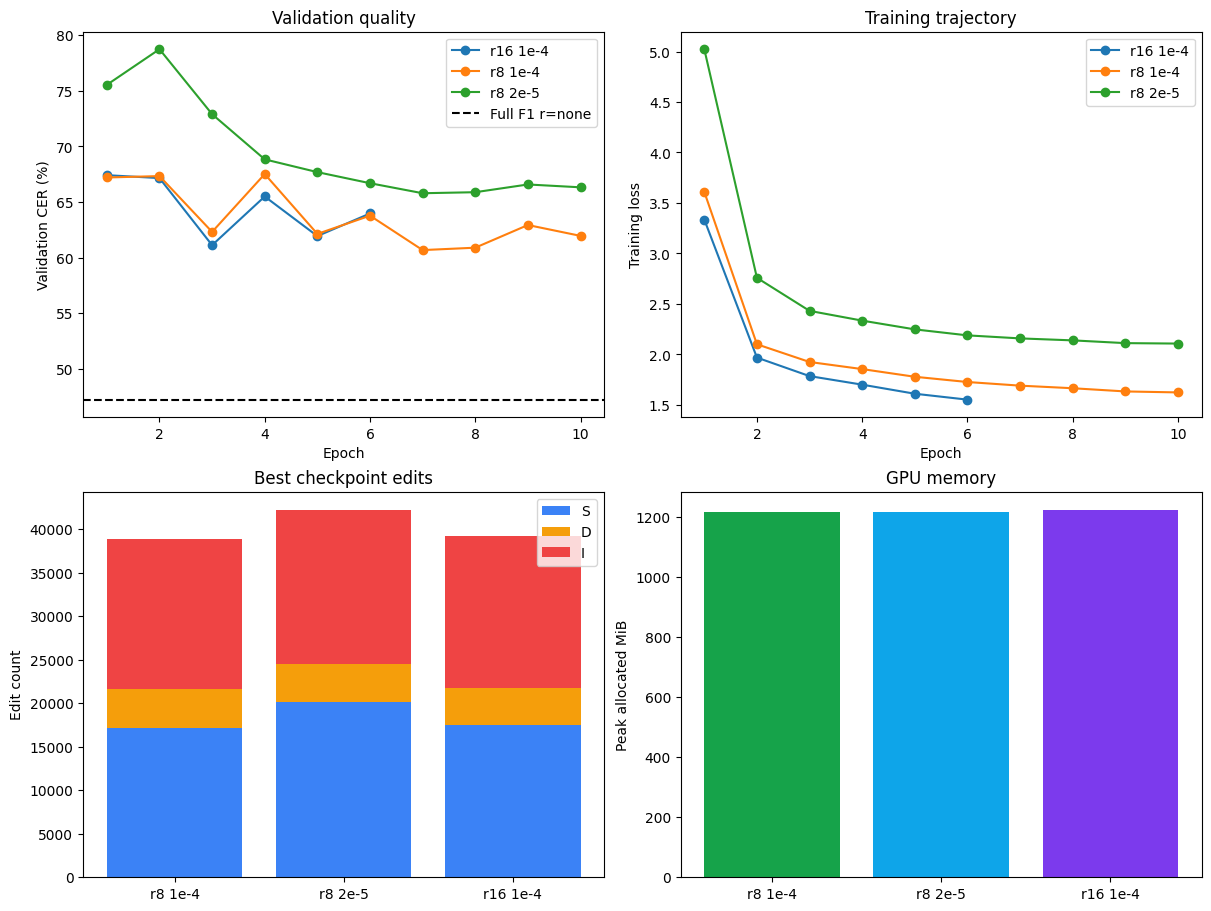

In [6]:
# Load aggregate histories and render publication-friendly figures.
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
run_dirs = {'r8 1e-4':'rank8_alpha16', 'r8 2e-5':'rank8_alpha16_lr2em5',
            'r16 1e-4':'rank16_alpha32'}
reports = {label:json.loads((ROOT/folder/'L1_report_private.json').read_text())
           for label,folder in run_dirs.items()}
rows, summaries = [], []
for label, report in reports.items():
    rank = report['lora_rank']
    assert report['test_data_used'] is False and report['train_clips']==3629 and report['validation_clips']==732
    assert report['lora_rank']==rank and report['repetition_penalty']==1.08
    for epoch in report['history']:
        v=epoch['validation']
        assert v['clips']==732 and v['reference_codepoints']==64137
        rows.append({'run':label,'rank':rank,'epoch':epoch['epoch'],'loss':epoch['training_loss'],
                     'CER_percent':100*v['corpus_cer'],'S':v['S'],'D':v['D'],'I':v['I'],
                     'EOS':v['eos_count'],'cap_hits':v['cap_without_eos'],
                     'minutes':epoch['epoch_seconds']/60,'peak_MiB':epoch['train_peak_allocated_mib']})
    best=next(x for x in report['history'] if x['epoch']==report['best_epoch'])['validation']
    summaries.append({'run':label,'rank':rank,'learning_rate':report['learning_rate'],
                      'best_epoch':report['best_epoch'],
                      'CER_percent':100*report['best_validation_cer'],'S':best['S'],'D':best['D'],'I':best['I'],
                      'EOS':best['eos_count'],'cap_hits':best['cap_without_eos'],
                      'trainable':report['trainable_parameters'],
                      'minutes':sum(x['epoch_seconds'] for x in report['history'])/60,
                      'peak_MiB':report['peak_allocated_mib']})
epochs=pd.DataFrame(rows); summary=pd.DataFrame(summaries)
display(epochs.round(3)); display(summary.round(3))
print('Full F1 reference: 2e-5, Epoch 5, 47.23950% CER, S/D/I 14503/5583/10212')
PLOTS=ROOT/'plots'; PLOTS.mkdir(exist_ok=True)
fig, axes=plt.subplots(2,2,figsize=(12,9),constrained_layout=True)
for label,g in epochs.groupby('run'):
    axes[0,0].plot(g.epoch,g.CER_percent,'o-',label=label)
    axes[0,1].plot(g.epoch,g.loss,'o-',label=label)
axes[0,0].axhline(47.239502939,ls='--',color='black',label='Full F1 r=none')
axes[0,0].set(xlabel='Epoch',ylabel='Validation CER (%)',title='Validation quality')
axes[0,1].set(xlabel='Epoch',ylabel='Training loss',title='Training trajectory')
bottom=[0]*len(summary)
for key,color in [('S','#3b82f6'),('D','#f59e0b'),('I','#ef4444')]:
    axes[1,0].bar(summary['run'],summary[key],bottom=bottom,label=key,color=color)
    bottom=[a+b for a,b in zip(bottom,summary[key])]
axes[1,0].set(ylabel='Edit count',title='Best checkpoint edits')
axes[1,1].bar(summary['run'],summary['peak_MiB'],color=['#16a34a','#0ea5e9','#7c3aed'])
axes[1,1].set(ylabel='Peak allocated MiB',title='GPU memory')
for ax in axes.flat:
    if ax==axes[1,0] or ax==axes[0,0] or ax==axes[0,1]: ax.legend()
fig.savefig(PLOTS/'lora_comparison.png',dpi=220,bbox_inches='tight')
plt.show()
epochs.to_csv(PLOTS/'epoch_metrics.csv',index=False)
summary.to_csv(PLOTS/'best_summary.csv',index=False)


## Download results and selected adapters

The results ZIP includes aggregate reports, private prediction JSONL files, and plots. Each adapter ZIP contains the selected adapter plus optimizer, scheduler, scaler, and RNG state for recovery. Keep these archives private.


In [ ]:
# Stream ZIP members from disk; avoid loading large checkpoints into memory.
import zipfile
from tqdm.auto import tqdm
from IPython.display import FileLink, display
results_zip=Path('/kaggle/working/phase7_L1_results_private.zip')
files=list(PLOTS.glob('*'))
for folder_name in run_dirs.values():
    folder=ROOT/folder_name
    files += [folder/'L1_report_private.json',folder/'aggregate_history.json']
    files += list(folder.glob('validation_epoch_*_private.jsonl'))
with zipfile.ZipFile(results_zip,'w',zipfile.ZIP_DEFLATED,allowZip64=True) as z:
    for path in tqdm(files,desc='Zipping results',unit='file'):
        assert path.is_file()
        z.write(path,path.relative_to(ROOT))
archives=[results_zip]
for label,report in reports.items():
    best=ROOT/run_dirs[label]/f"epoch_{report['best_epoch']:02d}"
    assert (best/'adapter'/'adapter_config.json').is_file() and (best/'training_state.pt').is_file()
    safe_label=label.replace(' ','_').replace('-','m')
    dest=Path(f'/kaggle/working/phase7_L1_{safe_label}_best_adapter_private.zip')
    with zipfile.ZipFile(dest,'w',zipfile.ZIP_STORED,allowZip64=True) as z:
        for path in tqdm([p for p in best.rglob('*') if p.is_file()],desc=f'{label} checkpoint',unit='file'):
            z.write(path,path.relative_to(best.parent))
    archives.append(dest)
for archive in archives:
    with zipfile.ZipFile(archive) as z: assert z.testzip() is None
    print(archive.name,round(archive.stat().st_size/2**20,2),'MiB')
    display(FileLink(str(archive)))


In [8]:
# ZIP the completed LoRA results and offer a browser download.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, Javascript, display
import json

results_dir = Path("/kaggle/working/phase7_L1_private")
zip_path = Path("/kaggle/working/phase7_L1_results.zip")

assert results_dir.is_dir(), f"Results folder not found: {results_dir}"

files = [p for p in results_dir.rglob("*") if p.is_file()]
assert files, "The results folder has no files to ZIP."

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for path in files:
        archive.write(path, path.relative_to(results_dir.parent))

print(f"Created: {zip_path}")
print(f"Files: {len(files)}")
print(f"Size: {zip_path.stat().st_size / 1024**2:.1f} MiB")

# This link is the reliable fallback if the automatic download is blocked.
display(FileLink(str(zip_path)))

# Ask the browser to start the download automatically.
display(Javascript(
    f'var a=document.createElement("a");'
    f'a.href={json.dumps("/files/" + zip_path.name)};'
    f'a.download={json.dumps(zip_path.name)};'
    'document.body.appendChild(a);a.click();a.remove();'
))

Created: /kaggle/working/phase7_L1_results.zip
Files: 142
Size: 106.8 MiB


/kaggle/working/phase7_L1_results.zip

<IPython.core.display.Javascript object>